In [21]:
!pip install -q qiskit qiskit-aer networkx matplotlib scipy

In [30]:
import itertools, numpy as np, networkx as nx
import matplotlib.pyplot as plt

# ESP32 nodes; weight = interference strength
scan = [("AP1", 1, 100), ("AP2", 11, 100), ("AP3", 11, 75),
        ("AP4", 6, 52), ("AP5", 6, 42), ("AP6", 6, 39)]
n = len(scan)
edges = [(i, j, round(5 * scan[i][2]/100 * scan[j][2]/100, 2))
         for i in range(n) for j in range(i+1, n)]
G = nx.Graph()
G.add_weighted_edges_from(edges)
W = sum(w for _,_,w in edges)

def cut_value(bits):  # bits[i] = channel of node i
    return sum(w for i,j,w in edges if bits[i] != bits[j])

best_classical, best_bits = max(
    ((cut_value(b), b) for b in itertools.product([0,1], repeat=n)))
print("Brute-force optimal cut:", best_classical, best_bits)

print(n, "APs;", len(edges), "weighted links; max weight", max(w for _,_,w in edges))

Brute-force optimal cut: 20.8 (1, 1, 0, 0, 0, 0)
6 APs; 15 weighted links; max weight 5.0


In [23]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

p = 2
params = ParameterVector("t", 2*p)

H = SparsePauliOp.from_sparse_list(
    [("ZZ", [i,j], w/2) for i,j,w in edges], num_qubits=n)

qc = QuantumCircuit(n)
qc.h(range(n))
for k in range(p):
    gamma, beta = params[2*k], params[2*k+1]
    for i,j,w in edges:
        qc.rzz(gamma*w, i, j)
    qc.rx(2*beta, range(n))

def energy(x):
    sv = Statevector(qc.assign_parameters(x))
    return sv.expectation_value(H).real

history, best = [], None
rng = np.random.default_rng(1)
for _ in range(8):  # random restarts
    x0 = rng.uniform(0, np.pi, 2*p)
    res = minimize(energy, x0, method="COBYLA",
                   callback=lambda xk: history.append(energy(xk)))
    if best is None or res.fun < best.fun:
        best = res

exp_cut = W/2 - best.fun
print("QAOA expected cut:", round(exp_cut,3))
print("Approximation ratio:", round(exp_cut/best_classical,3))

QAOA expected cut: 19.093
Approximation ratio: 0.918


Most likely channels: [1, 1, 0, 0, 1, 0] cut = 20.080000000000002 prob = 0.131


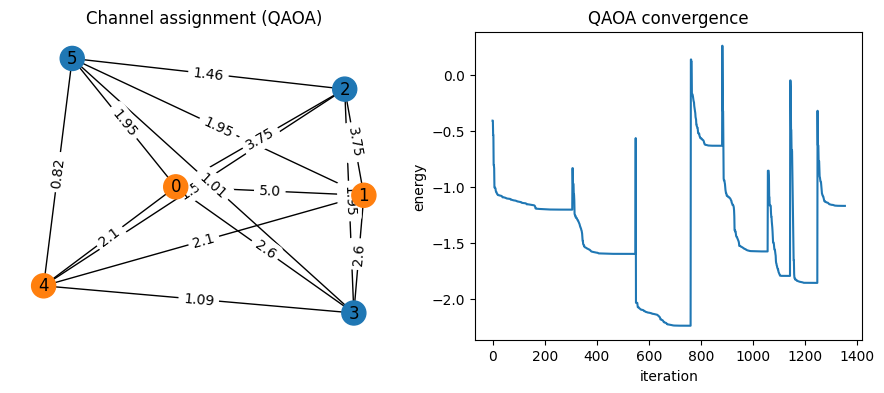

In [24]:
probs = Statevector(qc.assign_parameters(best.x)).probabilities_dict()
top = max(probs, key=probs.get)
bits = [int(c) for c in top[::-1]]  # Qiskit is little-endian
print("Most likely channels:", bits, "cut =", cut_value(bits),
      "prob =", round(probs[top],3))

fig, ax = plt.subplots(1,2, figsize=(11,4))
pos = nx.spring_layout(G, seed=3)
nx.draw(G, pos, ax=ax[0], with_labels=True,
        node_color=["tab:blue" if b==0 else "tab:orange" for b in bits])
nx.draw_networkx_edge_labels(G, pos, ax=ax[0],
        edge_labels=nx.get_edge_attributes(G,"weight"))
ax[0].set_title("Channel assignment (QAOA)")
ax[1].plot(history); ax[1].set_title("QAOA convergence")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("energy")
plt.show()

Optimal (brute force): 20.8
Random assignment (avg): 17.00  ratio 0.82
Greedy heuristic: 20.75  ratio 1.00
QAOA p=1: expected cut 17.53, ratio 0.843, P(optimal) 0.025
QAOA p=2: expected cut 19.21, ratio 0.924, P(optimal) 0.063
QAOA p=3: expected cut 19.32, ratio 0.929, P(optimal) 0.134


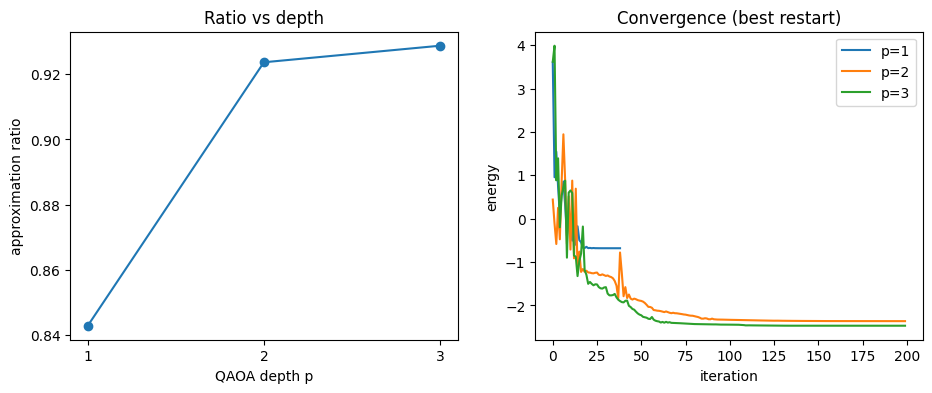

In [25]:
rng = np.random.default_rng(7)

def build(p):
    th = ParameterVector("t", 2*p)
    qc = QuantumCircuit(n); qc.h(range(n))
    for k in range(p):
        for i,j,w in edges: qc.rzz(th[2*k]*w, i, j)
        qc.rx(2*th[2*k+1], range(n))
    return qc

def run(p, restarts=6):
    qc, best, best_vals = build(p), None, None
    for _ in range(restarts):
        vals = []
        def f(x):
            v = Statevector(qc.assign_parameters(x)).expectation_value(H).real
            vals.append(v); return v
        res = minimize(f, rng.uniform(0, np.pi, 2*p),
                       method="COBYLA", options={"maxiter": 200})
        if best is None or res.fun < best.fun:
            best, best_vals = res, vals
    return qc, best, best_vals

def p_optimal(qc, x):
    probs = Statevector(qc.assign_parameters(x)).probabilities_dict()
    return sum(pr for s, pr in probs.items()
               if cut_value([int(c) for c in s[::-1]]) == best_classical)

# classical baselines
rand_cut = np.mean([cut_value(rng.integers(0, 2, n)) for _ in range(2000)])
side = {}
for v in range(n):  # greedy: put each node opposite its heavier neighbours
    gain0 = sum(w for i,j,w in edges if (i==v and side.get(j)==1) or (j==v and side.get(i)==1))
    gain1 = sum(w for i,j,w in edges if (i==v and side.get(j)==0) or (j==v and side.get(i)==0))
    side[v] = 0 if gain0 >= gain1 else 1
greedy_cut = cut_value([side[i] for i in range(n)])

print(f"Optimal (brute force): {best_classical}")
print(f"Random assignment (avg): {rand_cut:.2f}  ratio {rand_cut/best_classical:.2f}")
print(f"Greedy heuristic: {greedy_cut}  ratio {greedy_cut/best_classical:.2f}")

ratios, curves = [], {}
for p in [1, 2, 3]:
    qc_p, b, vals = run(p)
    r = (W/2 - b.fun) / best_classical
    ratios.append(r); curves[p] = vals
    print(f"QAOA p={p}: expected cut {W/2-b.fun:.2f}, ratio {r:.3f}, "
          f"P(optimal) {p_optimal(qc_p, b.x):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([1,2,3], ratios, "o-"); ax[0].set_xticks([1,2,3])
ax[0].set_xlabel("QAOA depth p"); ax[0].set_ylabel("approximation ratio")
ax[0].set_title("Ratio vs depth")
for p, v in curves.items(): ax[1].plot(v, label=f"p={p}")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("energy")
ax[1].set_title("Convergence (best restart)"); ax[1].legend()
plt.show()

p=1: [0.86, 0.859, 0.86, 0.857, 0.852]
p=3: [0.971, 0.955, 0.932, 0.91, 0.865]


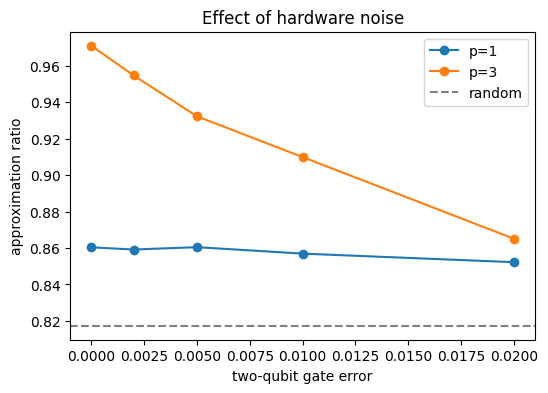

In [26]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import transpile

def exp_cut_from_counts(counts):
    tot = sum(counts.values())
    return sum(cnt * cut_value([int(c) for c in s[::-1]])
               for s, cnt in counts.items()) / tot

errs = [0, 0.002, 0.005, 0.01, 0.02]   # two-qubit gate error rates
noise_results = {}
for p in [1, 3]:
    qc_p, b, _ = run(p, restarts=4)      # optimise once, noise-free
    circ = qc_p.assign_parameters(b.x)
    circ.measure_all()
    out = []
    for e in errs:
        nm = NoiseModel()
        nm.add_all_qubit_quantum_error(depolarizing_error(e/10, 1), ["rz", "sx", "x"])
        nm.add_all_qubit_quantum_error(depolarizing_error(e, 2), ["cx"])
        sim = AerSimulator(noise_model=nm)
        t = transpile(circ, sim, basis_gates=["rz", "sx", "x", "cx"],
                      optimization_level=1)
        counts = sim.run(t, shots=8000).result().get_counts()
        out.append(exp_cut_from_counts(counts) / best_classical)
    noise_results[p] = out
    print(f"p={p}:", [round(v, 3) for v in out])

plt.figure(figsize=(6, 4))
for p, v in noise_results.items():
    plt.plot(errs, v, "o-", label=f"p={p}")
plt.axhline(rand_cut / best_classical, ls="--", c="gray", label="random")
plt.xlabel("two-qubit gate error"); plt.ylabel("approximation ratio")
plt.title("Effect of hardware noise"); plt.legend(); plt.show()

Best balanced (3 vs 3) cut, brute force: 20.75
lambda=0: feasibility yield 0.388, best feasible cut 20.53 (ratio 0.99), P(optimal balanced) 0.053
lambda=1: feasibility yield 0.525, best feasible cut 19.65 (ratio 0.95), P(optimal balanced) 0.015
lambda=2: feasibility yield 0.641, best feasible cut 19.65 (ratio 0.95), P(optimal balanced) 0.117
lambda=4: feasibility yield 0.472, best feasible cut 20.080000000000002 (ratio 0.97), P(optimal balanced) 0.052
lambda=8: feasibility yield 0.445, best feasible cut 20.080000000000002 (ratio 0.97), P(optimal balanced) 0.035


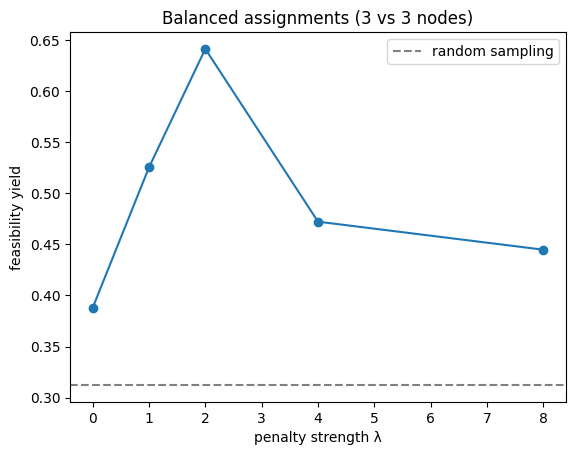

In [27]:
from itertools import product
best_bal = max(cut_value(b) for b in product([0,1], repeat=n) if sum(b) == n//2)
print("Best balanced (3 vs 3) cut, brute force:", best_bal)

def run_balanced(lam, p=2, restarts=6):
    # penalty lam*(sum x - n/2)^2  ->  adds lam to every pair's ZZ weight
    Wm = {(i, j): lam for i in range(n) for j in range(i+1, n)}
    for i, j, w in edges:
        Wm[(min(i,j), max(i,j))] += w
    Hb = SparsePauliOp.from_sparse_list(
        [("ZZ", [i, j], w/2) for (i, j), w in Wm.items()], num_qubits=n)
    th = ParameterVector("t", 2*p)
    qcb = QuantumCircuit(n); qcb.h(range(n))
    for k in range(p):
        for (i, j), w in Wm.items():
            qcb.rzz(th[2*k]*w, i, j)
        qcb.rx(2*th[2*k+1], range(n))
    f = lambda x: Statevector(qcb.assign_parameters(x)).expectation_value(Hb).real
    best = None
    for _ in range(restarts):
        res = minimize(f, rng.uniform(0, np.pi, 2*p), method="COBYLA",
                       options={"maxiter": 200})
        if best is None or res.fun < best.fun: best = res
    probs = Statevector(qcb.assign_parameters(best.x)).probabilities_dict()
    feas = {s: pr for s, pr in probs.items() if s.count("1") == n//2}
    top = max(feas, key=feas.get)
    bits = [int(c) for c in top[::-1]]
    p_opt = sum(pr for s, pr in feas.items()
                if cut_value([int(c) for c in s[::-1]]) == best_bal)
    return sum(feas.values()), cut_value(bits), p_opt

lams = [0, 1, 2, 4, 8]
yields = []
for lam in lams:
    y, c, po = run_balanced(lam)
    yields.append(y)
    print(f"lambda={lam}: feasibility yield {y:.3f}, "
          f"best feasible cut {c} (ratio {c/best_bal:.2f}), P(optimal balanced) {po:.3f}")

plt.plot(lams, yields, "o-")
plt.axhline(20/64, ls="--", c="gray", label="random sampling")
plt.xlabel("penalty strength λ"); plt.ylabel("feasibility yield")
plt.title("Balanced assignments (3 vs 3 nodes)"); plt.legend(); plt.show()

lambda=0: yield 0.52±0.18, best-cut ratio 0.94, P(optimal balanced) 0.123
lambda=1: yield 0.51±0.16, best-cut ratio 0.98, P(optimal balanced) 0.067
lambda=2: yield 0.59±0.06, best-cut ratio 0.93, P(optimal balanced) 0.089
lambda=4: yield 0.51±0.04, best-cut ratio 0.98, P(optimal balanced) 0.100
lambda=8: yield 0.41±0.07, best-cut ratio 0.93, P(optimal balanced) 0.081
Optimal balanced assignments: 4 -> random chance 0.0625


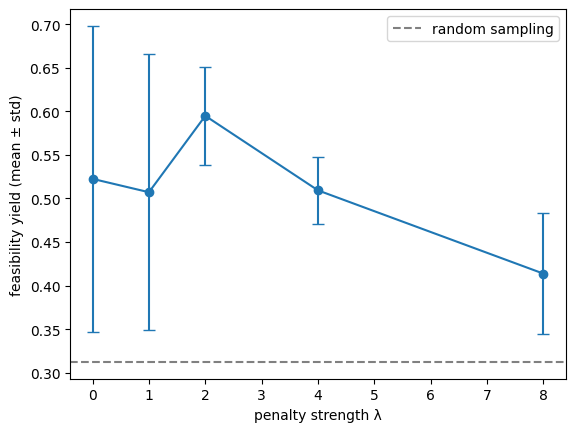

In [28]:
reps = 4
ys, ratios, pops = [], [], []
for lam in lams:
    r = [run_balanced(lam) for _ in range(reps)]
    ys.append([x[0] for x in r]); ratios.append([x[1]/best_bal for x in r])
    pops.append([x[2] for x in r])
    print(f"lambda={lam}: yield {np.mean(ys[-1]):.2f}±{np.std(ys[-1]):.2f}, "
          f"best-cut ratio {np.mean(ratios[-1]):.2f}, "
          f"P(optimal balanced) {np.mean(pops[-1]):.3f}")

n_opt = sum(1 for b in product([0,1], repeat=n)
            if sum(b)==n//2 and cut_value(b)==best_bal)
print("Optimal balanced assignments:", n_opt, "-> random chance", n_opt/64)

plt.errorbar(lams, [np.mean(y) for y in ys], [np.std(y) for y in ys], fmt="o-", capsize=4)
plt.axhline(20/64, ls="--", c="gray", label="random sampling")
plt.xlabel("penalty strength λ"); plt.ylabel("feasibility yield (mean ± std)")
plt.legend(); plt.show()

In [32]:
# Real Wi-Fi scan from Raspberry Pi 5, 2.4 GHz band, 6 access points
# (label, current channel, strongest signal % seen across 5 scans)
scan = [("AP1", 1, 100), ("AP2", 11, 100), ("AP3", 11, 75),
        ("AP4", 6, 52), ("AP5", 6, 42), ("AP6", 6, 39)]
n = len(scan)
# interference proxy between two APs = product of their signal strengths
edges = [(i, j, round(5 * scan[i][2]/100 * scan[j][2]/100, 2))
         for i in range(n) for j in range(i+1, n)]
print("Number of APs:", n)
print("Number of weighted links:", len(edges))
print("Maximum link weight:", max(w for _, _, w in edges))
print("Scan data:", scan)

Number of APs: 6
Number of weighted links: 15
Maximum link weight: 5.0
Scan data: [('AP1', 1, 100), ('AP2', 11, 100), ('AP3', 11, 75), ('AP4', 6, 52), ('AP5', 6, 42), ('AP6', 6, 39)]
